# Simple model: hit or bust
Predict `success`: **1 = hit** (revenue at least 2.5 times budget), **0 = bust** (below that benchmark). Use logistic regression with fixed settings and a 0.5 probability threshold. Report hit precision, recall, and F1, alongside accuracy and ROC AUC.

Use **9 predictors instead of 39**, read from the existing feature-engineering output. The original baseline is fixed. Optional Section 5 compares six compact feature presets without changing estimator settings or the success threshold. Run from this folder with `ds6001`; no CSVs or model files are written.

## 1. Load data and choose nine predictors
Use runtime, director experience, smoothed success rate of observed earlier director films and the number with known financial outcomes, certification, release month, sequel status, English-language status, and a director-history availability flag.

Four numeric predictors, two categorical predictors, and three binary indicators keep the model small. Counts are already `log1p` transformed in the source table. Both current-movie targets and identifiers are excluded from predictors.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, ConfusionMatrixDisplay

movies = pd.read_csv("../../data/model_data.csv", parse_dates=["release_date"])
movies = movies.sort_values("release_date", kind="stable").reset_index(drop=True)
NUMERIC_FEATURES = ["runtime", "dir_prior_films_log1p", "dir_prior_success_rate_smoothed", "dir_prior_known_films_log1p"]
CATEGORICAL_FEATURES = ["us_certification", "release_month"]
BINARY_FEATURES = ["is_sequel", "is_english", "dir_no_track_record"]
FEATURE_COLUMNS = NUMERIC_FEATURES + CATEGORICAL_FEATURES + BINARY_FEATURES
TARGET = "success"

assert len(FEATURE_COLUMNS) == 9
assert not {"success", "vote_average", "tmdb_id", "imdb_id", "title_tmdb", "release_date", "budget", "revenue"} & set(FEATURE_COLUMNS)
assert movies["tmdb_id"].is_unique and movies["release_date"].notna().all()
assert movies[BINARY_FEATURES].isin([0, 1]).all().all()
X = movies[FEATURE_COLUMNS].copy()
for column in CATEGORICAL_FEATURES:
    X[column] = X[column].map(lambda value: str(value) if pd.notna(value) else np.nan)
y = movies[TARGET].copy()
assert y.notna().all()
print(f"{len(movies):,} movies | 9 predictors | Target: {TARGET}")
display(pd.DataFrame({
    "Predictor": FEATURE_COLUMNS,
    "Role": ["Numeric"] * 4 + ["Categorical"] * 2 + ["Binary"] * 3,
}))
assert y.isin([0, 1]).all()

6,919 movies | 9 predictors | Target: success


,Predictor,Role
0,runtime,Numeric
1,dir_prior_films_log1p,Numeric
2,dir_prior_success_rate_smoothed,Numeric
3,dir_prior_known_films_log1p,Numeric
4,us_certification,Categorical
5,release_month,Categorical
6,is_sequel,Binary
7,is_english,Binary
8,dir_no_track_record,Binary


## 2. Split chronologically
Use the same earlier approximately 80% for training and later 20% for testing as the other models. Equal release dates stay together.

In [2]:
cutoff = movies.loc[int(len(movies) * 0.8), "release_date"]
train = movies["release_date"].lt(cutoff)
test = ~train
X_train, X_test = X.loc[train], X.loc[test]
y_train, y_test = y.loc[train], y.loc[test]
assert movies.loc[train, "release_date"].max() < movies.loc[test, "release_date"].min()
assert set(movies.loc[train, "tmdb_id"]).isdisjoint(movies.loc[test, "tmdb_id"])
display(pd.DataFrame([
    ["Training", len(y_train), movies.loc[train, "release_date"].min(), movies.loc[train, "release_date"].max()],
    ["Test", len(y_test), movies.loc[test, "release_date"].min(), movies.loc[test, "release_date"].max()],
], columns=["Split", "Movies", "First release", "Last release"]))

,Split,Movies,First release,Last release
0,Training,5535,1990-01-12,2017-11-17
1,Test,1384,2017-11-18,2025-12-25


## 3. Fit Logistic regression
Fit numeric medians/scaling and categorical imputation/one-hot encoding using training data only. Binary indicators pass through unchanged. All settings are fixed for this simple baseline.

In [3]:
preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), NUMERIC_FEATURES),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)),
    ]), CATEGORICAL_FEATURES),
    ("binary", "passthrough", BINARY_FEATURES),
])
model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(C=1.0, max_iter=3000, random_state=42)),
])
model.fit(X_train, y_train)
THRESHOLD = 0.5
train_probability = model.predict_proba(X_train)[:, list(model.classes_).index(1)]
test_probability = model.predict_proba(X_test)[:, list(model.classes_).index(1)]
train_prediction = (train_probability >= THRESHOLD).astype(int)
test_prediction = (test_probability >= THRESHOLD).astype(int)
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(np.zeros((len(y_train), 1)), y_train)
baseline_prediction = baseline.predict(np.zeros((len(y_test), 1)))
baseline_probability = baseline.predict_proba(np.zeros((len(y_test), 1)))[:, list(baseline.classes_).index(1)]

## 4. Evaluate
Compare the training and later-test results with a simple baseline, then inspect the first ten test predictions.

,Model,Split,Accuracy,Balanced accuracy,Hit precision,Hit recall,Hit F1,ROC AUC
0,Majority baseline,Test,0.6568,0.5000,0.0000,0.0000,0.0000,0.5000
1,Simple logistic regression,Training,0.6676,0.5789,0.6165,0.2464,0.3521,0.6617
2,Simple logistic regression,Test,0.6655,0.5940,0.5179,0.3663,0.4291,0.6608


,title_tmdb,success,hit_probability,predicted_success
5535,Revenge,0,0.487,0
5536,Darkest Hour,1,0.383,0
5537,"Three Billboards Outside Ebbing, Missouri",1,0.302,0
5538,The Shape of Water,1,0.319,0
5539,Wonder Wheel,0,0.296,0
5540,Molly's Game,0,0.494,0
5541,"I, Tonya",1,0.257,0
5542,Ferdinand,1,0.599,1
5543,Star Wars: The Last Jedi,1,0.775,1
5544,Loving Pablo,1,0.383,0


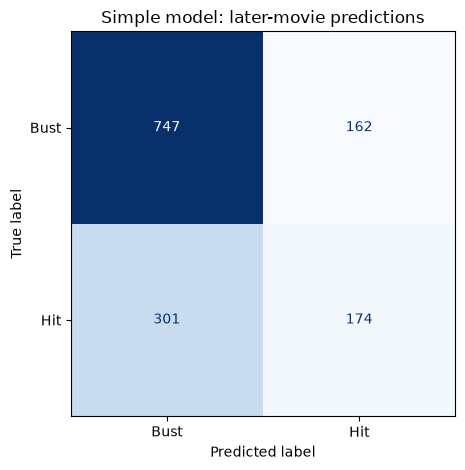

In [4]:
def score(name, split, actual, predicted, probability):
    return {
        "Model": name, "Split": split,
        "Accuracy": accuracy_score(actual, predicted),
        "Balanced accuracy": balanced_accuracy_score(actual, predicted),
        "Hit precision": precision_score(actual, predicted, zero_division=0),
        "Hit recall": recall_score(actual, predicted, zero_division=0),
        "Hit F1": f1_score(actual, predicted, zero_division=0),
        "ROC AUC": roc_auc_score(actual, probability),
    }
results = pd.DataFrame([
    score("Majority baseline", "Test", y_test, baseline_prediction, baseline_probability),
    score("Simple logistic regression", "Training", y_train, train_prediction, train_probability),
    score("Simple logistic regression", "Test", y_test, test_prediction, test_probability),
])
display(results.round(4))
examples = movies.loc[test, ["title_tmdb", "success"]].copy()
examples["hit_probability"] = test_probability
examples["predicted_success"] = test_prediction
display(examples.head(10).round(3))
ConfusionMatrixDisplay.from_predictions(
    y_test, test_prediction, labels=[0, 1], display_labels=["Bust", "Hit"],
    cmap="Blues", colorbar=False,
)
plt.title("Simple model: later-movie predictions")
plt.tight_layout()
plt.show()

## 5. Compare small feature sets
Try six named presets, each with **5–10 predictors**. Keep the same estimator settings and success threshold (0.5); only predictors change. Three expanding chronological validation folds stay entirely inside the original training period, with fresh preprocessing fitted in every fold.

Select the highest **mean validation hit F1**, requiring mean precision at least as high as the original nine-feature model. This retains the precision emphasis while F1 balances recall. The guard is based only on training-period predictions and does not guarantee higher test precision.

Refit the validation-selected preset on all training movies and compare it with the original nine-feature model on the same later test rows. Do not choose a preset from its test score. This is exploratory comparison on already-inspected data, not independent confirmation of improvement. You can edit `feature_versions` to define another small preset before rerunning.

In [5]:
from sklearn.model_selection import TimeSeriesSplit

basics = ["runtime", "us_certification", "release_month", "is_sequel", "is_english"]
feature_versions = {
    "Movie basics": basics,
    "+ Director experience": basics + ["dir_prior_films_log1p"],
    "Original director history": FEATURE_COLUMNS,
    "Actor/company/franchise": basics + [
        "lead_actor_films_5yr_backfilled_log1p", "backfill_unavailable",
        "company_films_5yr_log1p", "franchise_prior_films_log1p",
    ],
    "Basics + four genres": basics + ["genre_drama", "genre_comedy", "genre_action", "genre_horror"],
    "Compact mix": basics + [
        "dir_prior_success_rate_smoothed", "dir_prior_known_films_log1p", "dir_no_track_record",
        "lead_actor_films_5yr_backfilled_log1p", "company_films_5yr_log1p",
    ],
}
assert all(len(columns) <= 10 and len(columns) == len(set(columns)) for columns in feature_versions.values())
comparison_features = list(dict.fromkeys(column for columns in feature_versions.values() for column in columns))
assert not {"success", "vote_average", "tmdb_id", "imdb_id", "title_tmdb", "release_date", "budget", "revenue"} & set(comparison_features)
comparison_X = movies[comparison_features].copy()
for column in CATEGORICAL_FEATURES:
    comparison_X[column] = comparison_X[column].map(lambda value: str(value) if pd.notna(value) else np.nan)
comparison_binary = BINARY_FEATURES + ["backfill_unavailable"] + [column for column in movies if column.startswith("genre_")]

# Same model and preprocessing rules for every preset.
def make_feature_model(columns):
    numeric = [column for column in columns if column not in CATEGORICAL_FEATURES + comparison_binary]
    categorical = [column for column in CATEGORICAL_FEATURES if column in columns]
    binary = [column for column in columns if column in comparison_binary]
    return Pipeline([
        ("preprocessor", ColumnTransformer([
            ("numeric", Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
            ]), numeric),
            ("categorical", Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)),
            ]), categorical),
            ("binary", "passthrough", binary),
        ])),
        ("model", LogisticRegression(C=1.0, max_iter=3000, random_state=42)),
    ])

training_dates = movies.loc[train, "release_date"]
unique_dates = np.sort(training_dates.unique())
feature_splits = []
for earlier, later in TimeSeriesSplit(n_splits=3).split(unique_dates):
    fit_rows = training_dates.index[training_dates.isin(unique_dates[earlier])]
    validation_rows = training_dates.index[training_dates.isin(unique_dates[later])]
    assert movies.loc[fit_rows, "release_date"].max() < movies.loc[validation_rows, "release_date"].min()
    assert set(fit_rows).union(validation_rows).issubset(set(y_train.index))
    feature_splits.append((fit_rows, validation_rows))

fold_results = []
for version, columns in feature_versions.items():
    for fold, (fit_rows, validation_rows) in enumerate(feature_splits, 1):
        candidate = make_feature_model(columns)
        candidate.fit(comparison_X.loc[fit_rows], y.loc[fit_rows])
        probability = candidate.predict_proba(comparison_X.loc[validation_rows])[:, list(candidate.classes_).index(1)]
        predicted = (probability >= THRESHOLD).astype(int)
        metrics = score(version, "Validation", y.loc[validation_rows], predicted, probability)
        fold_results.append({"Version": version, "Fold": fold, "Predictors": len(columns), **{key: metrics[key] for key in ["Hit precision", "Hit recall", "Hit F1", "Balanced accuracy", "Accuracy", "ROC AUC"]}})
feature_fold_results = pd.DataFrame(fold_results)
feature_comparison = feature_fold_results.groupby("Version", sort=False).agg(
    Predictors=("Predictors", "first"),
    Precision=("Hit precision", "mean"), Recall=("Hit recall", "mean"),
    F1=("Hit F1", "mean"), F1_std=("Hit F1", "std"),
    Balanced_accuracy=("Balanced accuracy", "mean"), Accuracy=("Accuracy", "mean"),
    ROC_AUC=("ROC AUC", "mean"),
)
precision_floor = feature_comparison.loc["Original director history", "Precision"]
feature_comparison["Meets precision guard"] = feature_comparison["Precision"].ge(precision_floor - 1e-12)
eligible = feature_comparison.loc[feature_comparison["Meets precision guard"]]
selected_version = eligible.sort_values(["F1", "Precision"], ascending=False, kind="stable").index[0]
print(f"Validation precision guard (original nine-feature model): {precision_floor:.3f}")
with pd.option_context("display.max_columns", None):
    display(feature_comparison.round(4))
print("Selected using training-period validation:", selected_version)
selected_columns = feature_versions[selected_version]
print("Selected predictors:", selected_columns)

feature_selected_model = make_feature_model(selected_columns)
feature_selected_model.fit(comparison_X.loc[train], y_train)
selected_probability = feature_selected_model.predict_proba(comparison_X.loc[test])[:, list(feature_selected_model.classes_).index(1)]
selected_prediction = (selected_probability >= THRESHOLD).astype(int)
selected_test_result = score("Validation-selected simple model", "Test", y_test, selected_prediction, selected_probability)
comparison_test_results = pd.concat([results.loc[results["Split"].eq("Test")], pd.DataFrame([selected_test_result])], ignore_index=True)
display(comparison_test_results.round(4))
print("The original model above is retained. Lower test errors or higher classification scores are not guaranteed by validation selection.")
assert len(feature_fold_results) == 18


Validation precision guard (original nine-feature model): 0.596


,Predictors,Precision,Recall,F1,F1_std,Balanced_accuracy,Accuracy,ROC_AUC,Meets precision guard
Version,,,,,,,,,
Movie basics,5,0.5926,0.1737,0.2681,0.0826,0.5525,0.6467,0.6288,False
+ Director experience,6,0.6028,0.2022,0.3021,0.0650,0.5613,0.6503,0.6348,True
Original director history,9,0.5958,0.2156,0.3163,0.0755,0.5649,0.6520,0.6436,True
Actor/company/franchise,9,0.5879,0.1975,0.2954,0.0711,0.5581,0.6477,0.6348,False
Basics + four genres,9,0.6043,0.1833,0.2801,0.0761,0.5563,0.6493,0.6377,True
Compact mix,10,0.5953,0.1931,0.2903,0.0994,0.5593,0.6510,0.6443,False


Selected using training-period validation: Original director history
Selected predictors: ['runtime', 'dir_prior_films_log1p', 'dir_prior_success_rate_smoothed', 'dir_prior_known_films_log1p', 'us_certification', 'release_month', 'is_sequel', 'is_english', 'dir_no_track_record']


,Model,Split,Accuracy,Balanced accuracy,Hit precision,Hit recall,Hit F1,ROC AUC
0,Majority baseline,Test,0.6568,0.500,0.0000,0.0000,0.0000,0.5000
1,Simple logistic regression,Test,0.6655,0.594,0.5179,0.3663,0.4291,0.6608
2,Validation-selected simple model,Test,0.6655,0.594,0.5179,0.3663,0.4291,0.6608


The original model above is retained. Lower test errors or higher classification scores are not guaranteed by validation selection.


## Interpretation
Precision is how often a predicted hit is truly a hit; recall is how many actual hits are found. Hit F1 balances both equally. The fixed 0.5 threshold is a simple baseline, not a precision-optimized decision rule. Compare with the more detailed notebooks, which select features, settings, and thresholds through validation.

History covers observed earlier films and uses retrospective snapshots, not a complete director filmography or verified historical ratings/outcomes. Earlier-year histories update through time, representing rolling predictions. Results describe the financially eligible cohort and the already-inspected later period, so they are exploratory. Keep the same evaluation rows when comparing simple and detailed models.